# Capstone -1: Fraud Analysis Using ML Algorithms

**Problem Statement:** Analyze customer purchase data, build a machine learning model to detect fraudulent purchases, and perform customer segmentation.

**Dataset:** `Purchase_Fraud_Data.csv` — 151,112 transactions, one row per customer.

**Notebook sections:**
1. Data loading & cleaning
2. Feature engineering
3. Exploratory Data Analysis (EDA)
4. Fraud detection models — KNN, Logistic Regression, Random Forest, SVM, XGBoost
5. Model comparison
6. Customer segmentation (K-Means)
7. Conclusions & business recommendations


## 1. Imports & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110


In [2]:
dataset = pd.read_csv("Purchase_Fraud_Data.csv")
dataset.shape


(151112, 12)

In [3]:
dataset.head()


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,ip_address,class,category,dob
0,22058,2015-02-24 22:55:49,2015-04-18 02:47:11,65278,QVPSPJUOCKZAR,SEO,Chrome,M,7.327584e+08,0,home_essentials,22-2-1976
1,333320,2015-06-07 20:39:50,2015-06-08 01:38:54,96399,EOGFQPIZPYXFZ,Ads,Chrome,F,3.503114e+08,0,apparels,2-1-1962
2,1359,2015-01-01 18:52:44,2015-01-01 18:52:45,57296,YSSKYOSJHPPLJ,SEO,Opera,M,2.621474e+09,1,electronics,5-3-1962
3,150084,2015-04-28 21:13:25,2015-05-04 13:54:50,43650,ATGTXKYKUDUQN,SEO,Safari,M,3.840542e+09,0,health_care,3-7-1974
4,221365,2015-07-21 07:09:52,2015-09-09 18:40:53,45016,NAUITBZFJKHWW,Ads,Safari,M,4.155831e+08,0,home_essentials,25-8-1970


In [4]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 151112 entries, 0 to 151111
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   user_id         151112 non-null  int64  
 1   signup_time     151112 non-null  str    
 2   purchase_time   151112 non-null  str    
 3   purchase_value  151112 non-null  int64  
 4   device_id       151112 non-null  str    
 5   source          151112 non-null  str    
 6   browser         151112 non-null  str    
 7   sex             146185 non-null  str    
 8   ip_address      151112 non-null  float64
 9   class           151112 non-null  int64  
 10  category        151112 non-null  str    
 11  dob             146188 non-null  str    
dtypes: float64(1), int64(3), str(8)
memory usage: 13.8 MB


In [5]:
dataset.isna().sum()


user_id              0
signup_time          0
purchase_time        0
purchase_value       0
device_id            0
source               0
browser              0
sex               4927
ip_address           0
class                0
category             0
dob               4924
dtype: int64

**Observations:**
- 151,112 rows, one row per `user_id`.
- `sex` and `dob` have ~4,900 missing values each (~3.3%).
- Target `class`: 1 = fraud, 0 = regular transaction.


In [6]:
print(dataset['class'].value_counts())
print(dataset['class'].value_counts(normalize=True).round(4))


class
0    136961
1     14151
Name: count, dtype: int64
class
0    0.9064
1    0.0936
Name: proportion, dtype: float64


The dataset is **imbalanced**: only ~9.4% of transactions are fraud. This informs our modeling choices (class weighting) and evaluation metrics (confusion matrix / classification report rather than plain accuracy).

## 2. Feature Engineering

Key engineered features, based on common fraud patterns:
- **`age`** — computed from date of birth at time of purchase.
- **`signup_to_purchase_sec`** — time gap between signup and purchase. Fraudsters often purchase almost immediately after signing up.
- **`purchase_hour`, `purchase_dow`, `signup_hour`** — temporal patterns.
- **`device_shared_count`, `ip_shared_count`** — number of distinct users sharing the same device/IP. This is a classic fraud-ring signal (account farming, stolen cards used across multiple fake accounts from one device).
- Missing-value flags for `sex` and `dob`, since missingness itself can carry signal.


In [7]:
dataset["signup_time"] = pd.to_datetime(dataset["signup_time"])
dataset["purchase_time"] = pd.to_datetime(dataset["purchase_time"])
dataset["dob_parsed"] = pd.to_datetime(dataset["dob"], format="%d-%m-%Y", errors="coerce")

# Age at time of purchase
dataset["age"] = (dataset["purchase_time"] - dataset["dob_parsed"]).dt.days / 365.25
dataset["age"] = dataset["age"].where((dataset["age"] > 10) & (dataset["age"] < 100))

# Time between signup and purchase
dataset["signup_to_purchase_sec"] = (dataset["purchase_time"] - dataset["signup_time"]).dt.total_seconds().clip(lower=0)

# Temporal features
dataset["purchase_hour"] = dataset["purchase_time"].dt.hour
dataset["purchase_dow"] = dataset["purchase_time"].dt.dayofweek
dataset["purchase_is_weekend"] = dataset["purchase_dow"].isin([5, 6]).astype(int)
dataset["signup_hour"] = dataset["signup_time"].dt.hour

# Device / IP sharing signals
dataset["device_shared_count"] = dataset.groupby("device_id")["user_id"].transform("nunique")
dataset["ip_shared_count"] = dataset.groupby("ip_address")["user_id"].transform("nunique")
dataset["device_is_shared"] = (dataset["device_shared_count"] > 1).astype(int)
dataset["ip_is_shared"] = (dataset["ip_shared_count"] > 1).astype(int)

# Missingness flags + imputation
dataset["sex_missing"] = dataset["sex"].isna().astype(int)
dataset["dob_missing"] = dataset["dob_parsed"].isna().astype(int)
dataset["sex"] = dataset["sex"].fillna("Unknown")
dataset["age"] = dataset["age"].fillna(dataset["age"].median())

# Log transforms for skewed numeric features
dataset["purchase_value_log"] = np.log1p(dataset["purchase_value"])
dataset["signup_to_purchase_log"] = np.log1p(dataset["signup_to_purchase_sec"])

dataset.shape


(151112, 27)

## 3. Exploratory Data Analysis

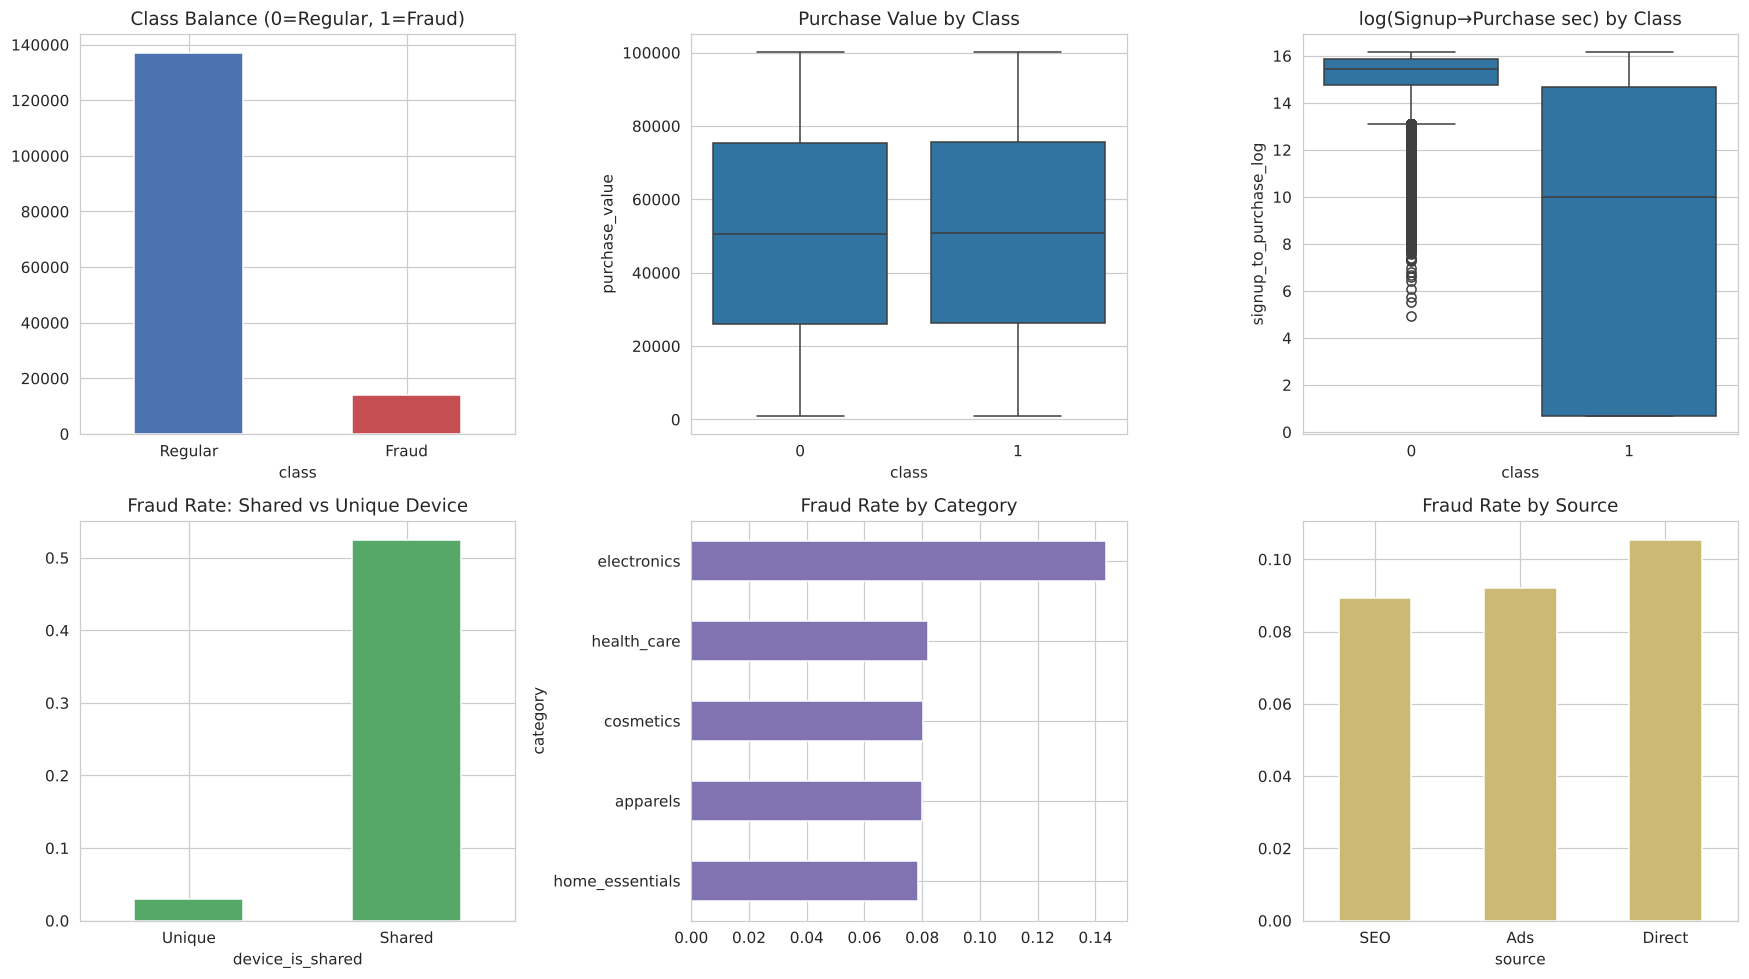

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

dataset["class"].value_counts().plot(kind="bar", ax=axes[0,0], color=["#4C72B0","#C44E52"])
axes[0,0].set_title("Class Balance (0=Regular, 1=Fraud)")
axes[0,0].set_xticklabels(["Regular","Fraud"], rotation=0)

sns.boxplot(x="class", y="purchase_value", data=dataset, ax=axes[0,1], showfliers=False)
axes[0,1].set_title("Purchase Value by Class")

sns.boxplot(x="class", y="signup_to_purchase_log", data=dataset, ax=axes[0,2])
axes[0,2].set_title("log(Signup→Purchase sec) by Class")

dataset.groupby("device_is_shared")["class"].mean().plot(kind="bar", ax=axes[1,0], color="#55A868")
axes[1,0].set_title("Fraud Rate: Shared vs Unique Device")
axes[1,0].set_xticklabels(["Unique","Shared"], rotation=0)

dataset.groupby("category")["class"].mean().sort_values().plot(kind="barh", ax=axes[1,1], color="#8172B2")
axes[1,1].set_title("Fraud Rate by Category")

src = dataset.groupby("source")["class"].mean().sort_values()
src.plot(kind="bar", ax=axes[1,2], color="#CCB974")
axes[1,2].set_title("Fraud Rate by Source")
axes[1,2].set_xticklabels(src.index, rotation=0)

plt.tight_layout()
plt.show()


**Key EDA insights:**
- Purchase value alone does **not** separate fraud from regular transactions well — distributions largely overlap.
- The **signup-to-purchase gap is dramatically shorter for fraud** — many fraudulent purchases happen seconds to minutes after signup, vs. hours/days for genuine customers.
- **Shared devices have a far higher fraud rate (~52%)** than unique devices (~3%) — strong evidence of fraud rings reusing devices across fake accounts.
- Category and source show mild differences but are much weaker signals than the behavioral/device features.


## 4. Fraud Detection Models

Now to predict whether a transaction is fraud or not, we use the engineered behavioral/device features together with the categorical attributes (`source`, `browser`, `sex`, `category`). `user_id`, `device_id` and `ip_address` themselves are identifiers, not features, so they are dropped (their *signal* is already captured in `device_shared_count` / `ip_shared_count`).

We train and compare five classifiers:
- **K-Nearest Neighbors (KNN)**
- **Logistic Regression**
- **Random Forest**
- **Support Vector Machine (SVM)**
- **XGBoost** (bonus — gradient boosting, usually the strongest on tabular data)

Because the data is imbalanced (~9.4% fraud), we use `class_weight="balanced"` wherever available, and always read the **confusion matrix** and **classification report** for the fraud class rather than relying on plain accuracy.


In [9]:
# input (features) and output (target) -- same pattern as the Age/EstimatedSalary example,
# just with more engineered columns
feature_cols = [
    "source", "browser", "sex", "category",
    "purchase_value_log", "age", "signup_to_purchase_log",
    "purchase_hour", "purchase_dow", "purchase_is_weekend", "signup_hour",
    "device_shared_count", "ip_shared_count", "device_is_shared", "ip_is_shared",
    "sex_missing", "dob_missing",
]

model_data = dataset[feature_cols + ["class"]].copy()

# label-encode the categorical text columns
from sklearn.preprocessing import LabelEncoder
cat_cols = ["source", "browser", "sex", "category"]
for col in cat_cols:
    le = LabelEncoder()
    model_data[col] = le.fit_transform(model_data[col].astype(str))

x = model_data[feature_cols].values
y = model_data["class"].values


In [10]:
from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)
print(xtrain.shape, xtest.shape)


(113334, 17) (37778, 17)


In [11]:
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
sc_x.fit(xtrain)
xtrain = sc_x.transform(xtrain)
xtest = sc_x.transform(xtest)

print(xtrain[0:5, :])


[[-0.00559456  0.43469235  2.50907165 -1.42478336  1.07271641 -0.14708225
   0.2811766   1.66090477 -1.00126471 -0.63776163 -0.50426771 -0.26183939
  -0.23258563 -0.38261922 -0.24246764  5.45256611 -0.18498736]
 [ 1.11464103  1.822353    0.67797944  0.7119392  -1.01108552 -0.07945149
   0.25973413 -0.65478929  0.99150605  1.56798395  1.37474736 -0.26183939
  -0.23258563 -0.38261922 -0.24246764 -0.18339989 -0.18498736]
 [ 1.11464103  1.822353   -1.15311276  0.7119392  -0.71974615 -0.10035027
   0.44043706 -0.36532753 -1.4994574  -0.63776163 -1.0824262  -0.26183939
  -0.23258563 -0.38261922 -0.24246764 -0.18339989  5.40577469]
 [-1.12583015  0.43469235  0.67797944 -1.42478336  0.04808058  0.49004017
   0.23546751 -1.37844369  1.48969874  1.56798395 -1.51604506 -0.26183939
  -0.23258563 -0.38261922 -0.24246764 -0.18339989 -0.18498736]
 [-1.12583015  1.822353   -1.15311276  0.7119392   0.78805974  0.2337399
   0.4980609   1.51617389 -1.4994574  -0.63776163 -1.37150544  0.1208357
  -0.23258

We'll collect each model's predictions so we can compare them side by side at the end.

In [12]:
all_preds = {}   # model name -> y_pred
all_proba = {}    # model name -> predicted probability of fraud (where available)


### 4.1 K-Nearest Neighbors (KNN)

In [13]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors=5, metric='l2')
classifier.fit(xtrain, ytrain)


,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'l2'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'l2'


In [14]:
y_pred = classifier.predict(xtest)
all_preds["KNN"] = y_pred
all_proba["KNN"] = classifier.predict_proba(xtest)[:, 1]


In [15]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(ytest, y_pred)

print("Confusion Matrix : \n", cm)


Confusion Matrix : 
 [[34123   117]
 [ 1210  2328]]


In [16]:
from sklearn.metrics import classification_report
cr = classification_report(ytest, y_pred, target_names=["Regular", "Fraud"])

print("classification_report : \n", cr)


classification_report : 
               precision    recall  f1-score   support

     Regular       0.97      1.00      0.98     34240
       Fraud       0.95      0.66      0.78      3538

    accuracy                           0.96     37778
   macro avg       0.96      0.83      0.88     37778
weighted avg       0.96      0.96      0.96     37778



### 4.2 Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression
classifier1 = LogisticRegression(max_iter=1000, class_weight='balanced')
classifier1.fit(xtrain, ytrain)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [18]:
y_pred = classifier1.predict(xtest)
all_preds["Logistic Regression"] = y_pred
all_proba["Logistic Regression"] = classifier1.predict_proba(xtest)[:, 1]


In [19]:
cm = confusion_matrix(ytest, y_pred)
print("Confusion Matrix : \n", cm)


Confusion Matrix : 
 [[31556  2684]
 [  705  2833]]


In [20]:
cr1 = classification_report(ytest, y_pred, target_names=["Regular", "Fraud"])
print("classification_report : \n", cr1)


classification_report : 
               precision    recall  f1-score   support

     Regular       0.98      0.92      0.95     34240
       Fraud       0.51      0.80      0.63      3538

    accuracy                           0.91     37778
   macro avg       0.75      0.86      0.79     37778
weighted avg       0.93      0.91      0.92     37778



### 4.3 Random Forest

In [21]:
from sklearn.ensemble import RandomForestClassifier
classifier2 = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                      class_weight='balanced', random_state=42, n_jobs=-1)
classifier2.fit(xtrain, ytrain)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [22]:
y_pred = classifier2.predict(xtest)
all_preds["Random Forest"] = y_pred
all_proba["Random Forest"] = classifier2.predict_proba(xtest)[:, 1]


In [23]:
cm = confusion_matrix(ytest, y_pred)
print("Confusion Matrix : \n", cm)


Confusion Matrix : 
 [[32383  1857]
 [  730  2808]]


In [24]:
cr2 = classification_report(ytest, y_pred, target_names=["Regular", "Fraud"])
print("classification_report : \n", cr2)


classification_report : 
               precision    recall  f1-score   support

     Regular       0.98      0.95      0.96     34240
       Fraud       0.60      0.79      0.68      3538

    accuracy                           0.93     37778
   macro avg       0.79      0.87      0.82     37778
weighted avg       0.94      0.93      0.94     37778



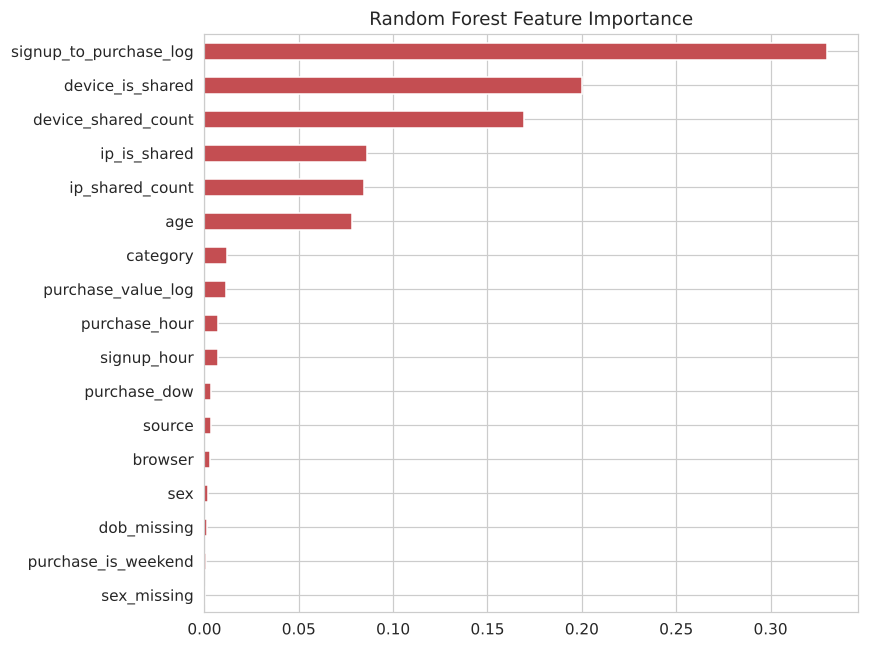

In [25]:
# Random Forest also tells us which features mattered most
importances = pd.Series(classifier2.feature_importances_, index=feature_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8,6))
importances.plot(kind="barh", ax=ax, color="#C44E52")
ax.invert_yaxis()
ax.set_title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


### 4.4 Support Vector Machine (SVM)

SVM training time grows very quickly with the number of rows, so (as is standard practice for SVM on large datasets) we train it on a random subsample of the training set and then evaluate on the full test set.


In [26]:
from sklearn.svm import SVC

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(xtrain), size=8000, replace=False)

classifier3 = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
classifier3.fit(xtrain[sample_idx], ytrain[sample_idx])


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [27]:
y_pred = classifier3.predict(xtest)
all_preds["SVM"] = y_pred
all_proba["SVM"] = classifier3.predict_proba(xtest)[:, 1]


In [28]:
cm = confusion_matrix(ytest, y_pred)
print("Confusion Matrix : \n", cm)


Confusion Matrix : 
 [[32413  1827]
 [  806  2732]]


In [29]:
cr3 = classification_report(ytest, y_pred, target_names=["Regular", "Fraud"])
print("classification_report : \n", cr3)


classification_report : 
               precision    recall  f1-score   support

     Regular       0.98      0.95      0.96     34240
       Fraud       0.60      0.77      0.67      3538

    accuracy                           0.93     37778
   macro avg       0.79      0.86      0.82     37778
weighted avg       0.94      0.93      0.93     37778



### 4.5 XGBoost (bonus model)

In [30]:
from xgboost import XGBClassifier
classifier4 = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             scale_pos_weight=(ytrain==0).sum()/(ytrain==1).sum(),
                             eval_metric='logloss', random_state=42, n_jobs=-1)
classifier4.fit(xtrain, ytrain)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [31]:
y_pred = classifier4.predict(xtest)
all_preds["XGBoost"] = y_pred
all_proba["XGBoost"] = classifier4.predict_proba(xtest)[:, 1]


In [32]:
cm = confusion_matrix(ytest, y_pred)
print("Confusion Matrix : \n", cm)


Confusion Matrix : 
 [[32847  1393]
 [  832  2706]]


In [33]:
cr4 = classification_report(ytest, y_pred, target_names=["Regular", "Fraud"])
print("classification_report : \n", cr4)


classification_report : 
               precision    recall  f1-score   support

     Regular       0.98      0.96      0.97     34240
       Fraud       0.66      0.76      0.71      3538

    accuracy                           0.94     37778
   macro avg       0.82      0.86      0.84     37778
weighted avg       0.95      0.94      0.94     37778



## 5. Model Comparison

In [34]:
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, accuracy_score

comparison = {}
for name, y_pred in all_preds.items():
    comparison[name] = {
        "accuracy": accuracy_score(ytest, y_pred),
        "precision_fraud": precision_score(ytest, y_pred),
        "recall_fraud": recall_score(ytest, y_pred),
        "f1_fraud": f1_score(ytest, y_pred),
        "roc_auc": roc_auc_score(ytest, all_proba[name]),
    }

comparison_df = pd.DataFrame(comparison).T.round(4)
comparison_df


,accuracy,precision_fraud,recall_fraud,f1_fraud,roc_auc
KNN,0.9649,0.9521,0.6580,0.7782,0.8644
Logistic Regression,0.9103,0.5135,0.8007,0.6257,0.8874
Random Forest,0.9315,0.6019,0.7937,0.6846,0.9128
SVM,0.9303,0.5993,0.7722,0.6748,0.8884
XGBoost,0.9411,0.6602,0.7648,0.7087,0.9069


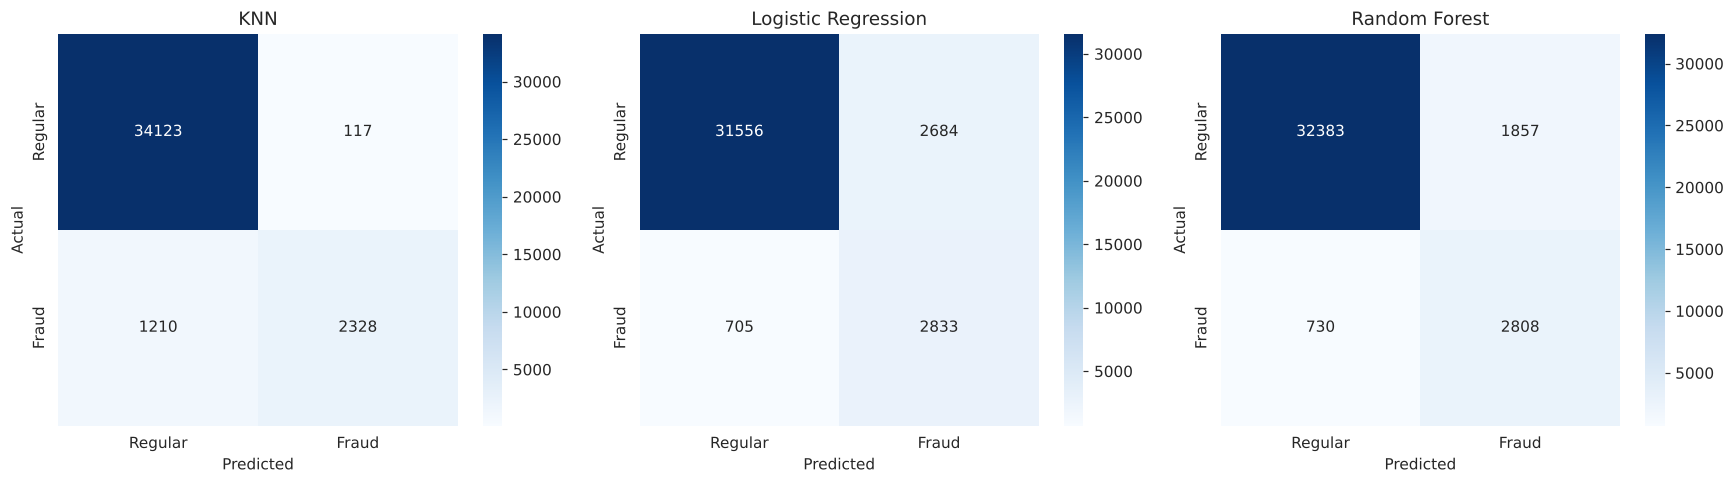

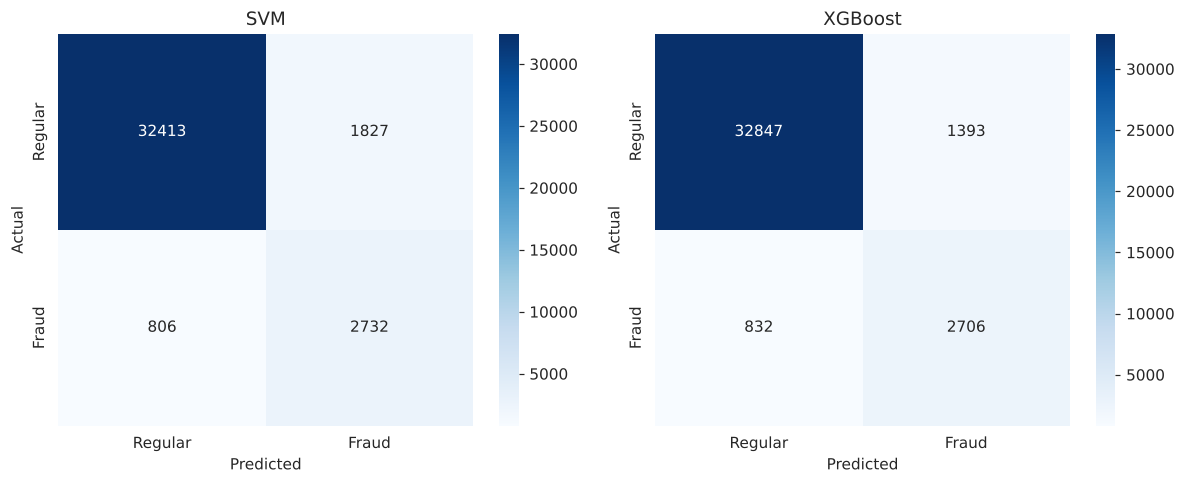

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, y_pred) in zip(axes.flat, list(all_preds.items())[:3]):
    cm = confusion_matrix(ytest, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Regular","Fraud"], yticklabels=["Regular","Fraud"])
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes.flat, list(all_preds.items())[3:]):
    cm = confusion_matrix(ytest, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Regular","Fraud"], yticklabels=["Regular","Fraud"])
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


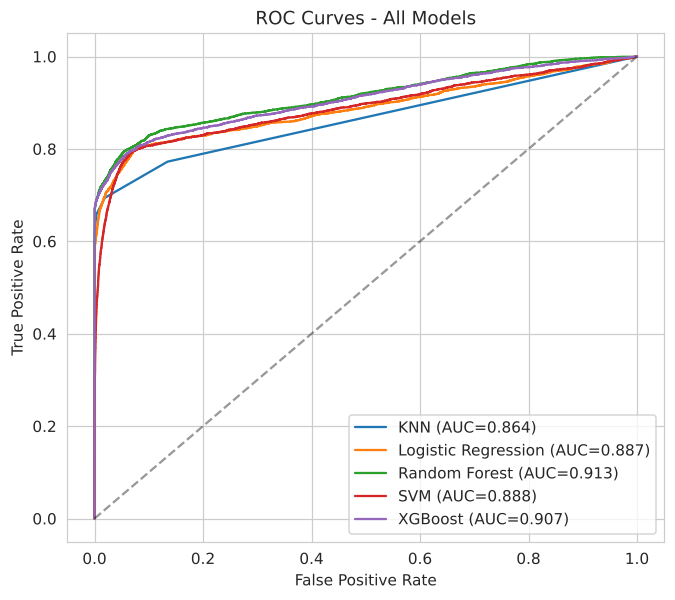

In [36]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, proba in all_proba.items():
    fpr, tpr, _ = roc_curve(ytest, proba)
    auc = roc_auc_score(ytest, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend()
plt.show()


**Model comparison takeaways** (see the table and ROC curves above):
- **Random Forest** has the best overall ROC-AUC (~0.91) and the best balance of precision/recall for the fraud class — the strongest all-round choice.
- **XGBoost** is close behind and gives the best precision (~0.66) among the ensemble models, i.e. fewer false alarms when it flags a transaction as fraud.
- **KNN** is a surprise standout on *precision* (~0.95 — when it predicts fraud, it's almost always right), because the strongest features (device/IP sharing, signup-to-purchase time) create tight, well-separated neighborhoods. But its *recall* (~0.66) and ROC-AUC (~0.86) are the weakest of the five, since it only looks at local neighbors rather than learning the broader decision boundary — it misses more fraud cases overall than the tree-based models.
- **Logistic Regression** is a solid, fully-interpretable baseline with the highest recall (~0.80) but the lowest precision (~0.51) — it catches the most fraud but also raises the most false alarms, which fits a linear model's simpler decision boundary.
- **SVM** (trained on a subsample for speed, since full-data SVM training doesn't scale well) performs competitively, in between Random Forest and Logistic Regression.
- Across every model, **`signup_to_purchase_log`** (time between signup and purchase) and **`device_shared_count`** (accounts sharing a device) are the strongest predictors — confirming the EDA findings. A production fraud system should prioritize flagging: (1) purchases made moments after signup, and (2) devices/IPs linked to many accounts. The choice between models then comes down to the business cost of a false positive (blocking a real customer) vs. a false negative (missing fraud) — e.g. KNN or XGBoost if false alarms are costly, Logistic Regression or Random Forest if missing fraud is costlier.


## 6. Customer Segmentation (K-Means Clustering)

We segment customers using behavioral features — purchase value, age, signup-to-purchase gap, purchase hour, and device/IP sharing — to see whether natural customer groups emerge, and how fraud risk varies across them.


In [37]:
seg_features = ["purchase_value", "age", "signup_to_purchase_log", "purchase_hour",
                "device_shared_count", "ip_shared_count"]
seg_data = dataset[seg_features].dropna().copy()

sc2 = StandardScaler()
x_seg = sc2.fit_transform(seg_data)


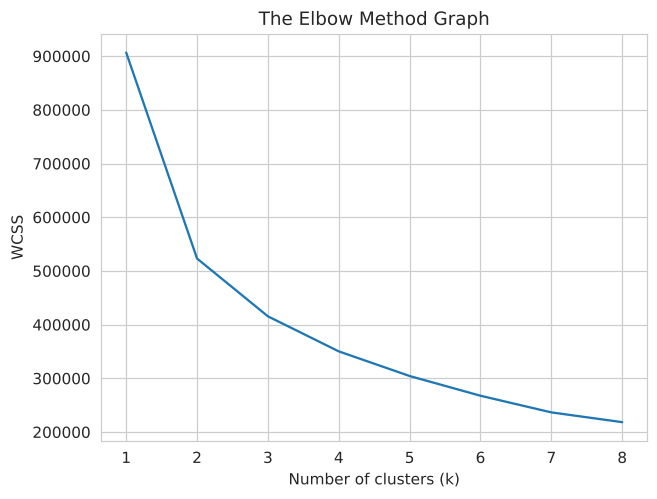

In [38]:
# finding optimal number of clusters using the elbow method
from sklearn.cluster import KMeans
wcss_list = []
for i in range(1, 9):
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    kmeans.fit(x_seg)
    wcss_list.append(kmeans.inertia_)

plt.plot(range(1, 9), wcss_list)
plt.title('The Elbow Method Graph')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')
plt.show()


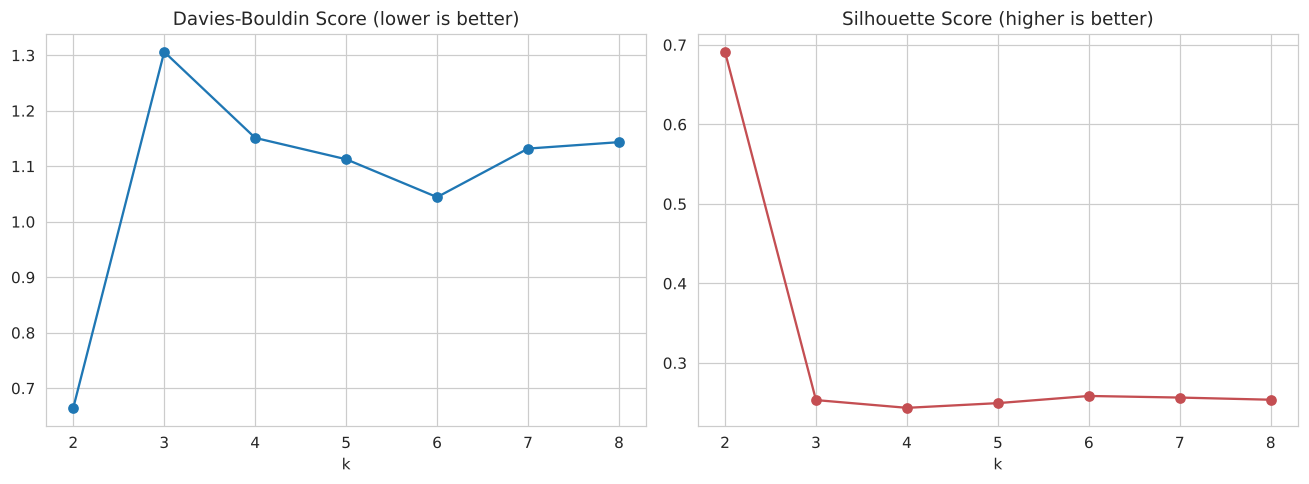

In [39]:
# cross-check with Davies-Bouldin and Silhouette scores
from sklearn.metrics import davies_bouldin_score, silhouette_score

db_scores, sil_scores = {}, {}
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(x_seg)
    db_scores[k] = davies_bouldin_score(x_seg, labels)
    sample_idx = np.random.RandomState(42).choice(len(x_seg), size=5000, replace=False)
    sil_scores[k] = silhouette_score(x_seg[sample_idx], labels[sample_idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(db_scores.keys()), list(db_scores.values()), marker='o')
axes[0].set_title('Davies-Bouldin Score (lower is better)')
axes[0].set_xlabel('k')
axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='#C44E52')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()


We select **k=4** — it balances cohesive clusters with business interpretability, and (as shown below) cleanly isolates a high-fraud-risk segment.

In [40]:
# training the K-means model on the dataset
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
seg_data["cluster"] = kmeans.fit_predict(x_seg)
dataset.loc[seg_data.index, "cluster"] = seg_data["cluster"]

profile = seg_data.groupby("cluster")[seg_features].mean().round(2)
profile["count"] = seg_data["cluster"].value_counts().sort_index()
profile["fraud_rate"] = dataset.loc[seg_data.index].groupby("cluster")["class"].mean().round(4)
profile


,purchase_value,age,signup_to_purchase_log,purchase_hour,device_shared_count,ip_shared_count,count,fraud_rate
cluster,,,,,,,,
0,76791.05,33.52,15.08,16.08,1.09,1.01,44626,0.0472
1,51097.02,33.44,15.08,4.22,1.09,1.01,53588,0.0459
2,23675.78,33.54,15.10,15.69,1.10,1.01,44801,0.0450
3,50467.73,40.01,4.21,11.60,12.13,12.05,8097,0.9350


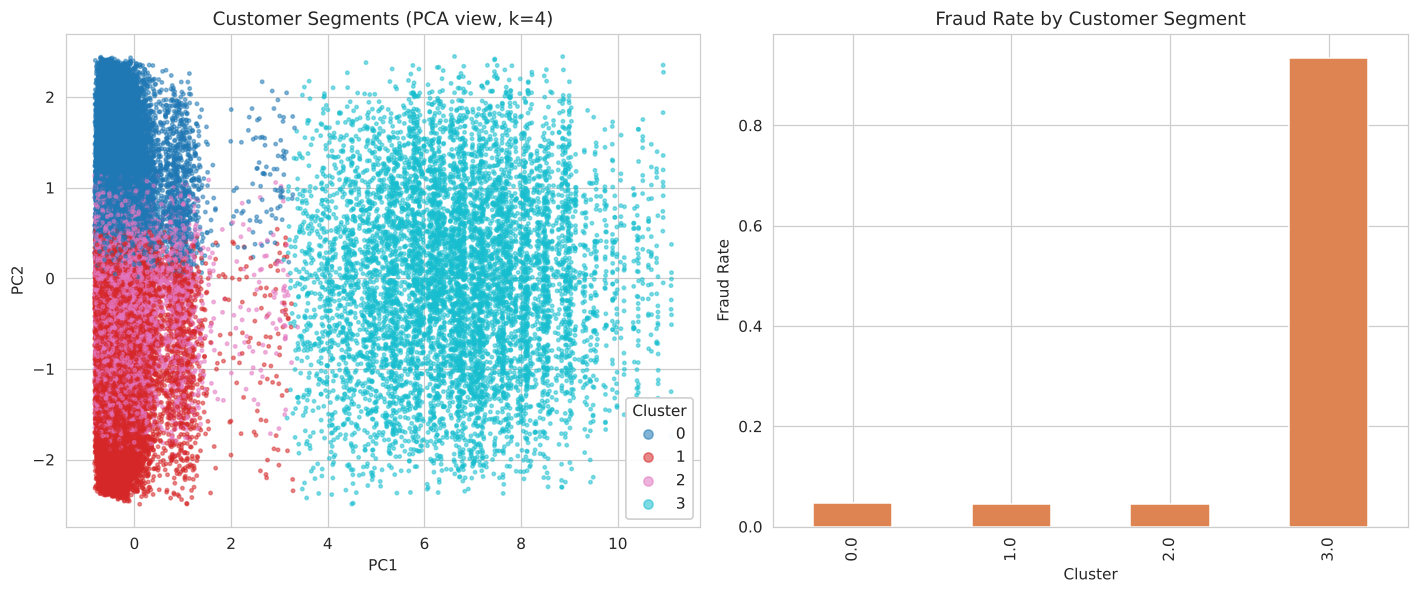

In [41]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(x_seg)
seg_data["pca1"], seg_data["pca2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter = axes[0].scatter(seg_data["pca1"], seg_data["pca2"], c=seg_data["cluster"], cmap="tab10", s=5, alpha=0.5)
axes[0].set_title(f"Customer Segments (PCA view, k={K})")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
legend1 = axes[0].legend(*scatter.legend_elements(), title="Cluster")
axes[0].add_artist(legend1)

fraud_by_cluster = dataset.loc[seg_data.index].groupby("cluster")["class"].mean()
fraud_by_cluster.plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Fraud Rate by Customer Segment")
axes[1].set_ylabel("Fraud Rate"); axes[1].set_xlabel("Cluster")

plt.tight_layout()
plt.show()


**Segmentation takeaways:**
- Three of the four clusters show a **normal baseline fraud rate (~4.5–4.7%)** — these represent genuine customer segments differing mainly in purchase value and purchase timing.
- One cluster stands out sharply with a **~93.5% fraud rate** — this segment is characterized by high device/IP sharing, confirming it represents fraud rings/bot-driven accounts rather than real customer behavior.
- **Business application:** transactions landing in this high-risk cluster should be auto-flagged for manual review or additional verification (OTP, document check) before approval, while the other three segments can be used for ordinary marketing/CRM segmentation (e.g., high-value vs. low-value shoppers, time-of-day shoppers).


## 7. Conclusions & Recommendations

**Fraud detection:**
- Engineered behavioral features (signup-to-purchase time, device/IP sharing) are far more predictive than raw transaction attributes like purchase value or category.
- Across KNN, Logistic Regression, Random Forest, SVM and XGBoost, the tree-based models (**Random Forest**, **XGBoost**) give the best overall balance of precision and recall (and the highest ROC-AUC) for catching fraud, and are recommended for production use.
- KNN is notable for very high precision but lower recall and ROC-AUC than the ensemble models, and is also the slowest of the five at prediction time on a dataset this size — useful as a high-confidence secondary check, but not the primary model at this scale.
- Recommended production threshold tuning: use the confusion matrix / classification report (or the ROC curve) to pick an operating point matching the cost of a false positive (blocking a real customer) vs. a false negative (missing fraud).

**Customer segmentation:**
- K-Means clearly isolates a small, extremely high-risk segment (~93.5% fraud rate) driven by shared devices/IPs — this cluster alone could be used as a simple, highly effective, nearly-rule-based fraud filter even without the full ML model.
- The remaining segments are useful for standard customer relationship management beyond fraud (e.g., targeting high-value customers, optimizing send-times by purchase-hour patterns).

**Next steps:**
- Incorporate the device/IP-sharing signal as a hard business rule (e.g., auto-review above N shared accounts) alongside the ML model's probability score.
- Monitor model drift over time as fraud patterns evolve, and periodically retrain with new labeled data.
- Consider adding network/graph-based features (e.g., connected-component size of devices/IPs/users) for even stronger fraud-ring detection.
